In [1]:
from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

from openfermion.transforms import get_fermion_operator, jordan_wigner
from openfermion.linalg import get_ground_state, get_sparse_operator
import numpy
import scipy
import scipy.linalg

from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer


import itertools
from collections import OrderedDict

import numpy as np

from mindquantum.core.circuit import Circuit, decompose_single_term_time_evolution
from mindquantum.core.operators import FermionOperator, down_index, up_index
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.utils.type_value_check import _require_package

from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import random
import matplotlib.pyplot as plt

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")

[WARNING] ME(798557:132302941265920,MainProcess):2025-06-07-15:50:33.210.000 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [2]:
def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):  # pylint: disable=too-many-locals,too-many-statements
    """
    Generate a uccsd quantum circuit.

    Args:
        mol (molecular): A hdf5 molecular file generated by HiQ Fermion.
        threshold (float, optional): A threshold of parameters. If the absolute value of parameter is
            lower than the threshold, than we will not update it in VQE
            algorithm. Default: ``0``.
    """
    if n_qubits == 0:
        n_qubits = mol.n_qubits
        n_electrons = mol.n_electrons
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    out_tmp = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied

    # Unpack amplitudes
    n_single_amplitudes = n_occupied * n_virtual
    # Generate excitations
    spin_index_functions = [up_index, down_index]
    # Generate all spin-conserving single and double excitations derived
    # from one spatial occupied-virtual pair
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):  # pylint: disable=invalid-name
        # Get indices of spatial orbitals
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up = virtual_spatial * 2
        occupied_up = occupied_spatial * 2
        virtual_down = virtual_spatial * 2 + 1
        occupied_down = occupied_spatial * 2 + 1
        single_amps = mol.ccsd_single_amps[virtual_up, occupied_up]
        double1_amps = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        single_amps_name = 'p' + str(i)
        double1_amps_name = 'p' + str(i + n_single_amplitudes)

        for spin in range(2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            this_index = spin_index_functions[spin]
            other_index = spin_index_functions[1 - spin]

            # Get indices of spin orbitals
            virtual_this = this_index(virtual_spatial)
            virtual_other = other_index(virtual_spatial)
            occupied_this = this_index(occupied_spatial)
            occupied_other = other_index(occupied_spatial)

            # Generate single excitations
            if abs(single_amps) > threshold:
                params[single_amps_name] = single_amps
                fermion_ops1 = FermionOperator(((occupied_this, 1), (virtual_this, 0)), 1)
                fermion_ops2 = FermionOperator(((virtual_this, 1), (occupied_this, 0)), 1)
                out.append([fermion_ops1 - fermion_ops2, single_amps_name])

            # Generate double excitation
            if abs(double1_amps) > threshold:
                params[double1_amps_name] = double1_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_this, 1), (occupied_this, 0), (virtual_other, 1), (occupied_other, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_other, 1), (virtual_other, 0), (occupied_this, 1), (virtual_this, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double1_amps_name])
    out.extend(out_tmp)
    out_tmp = []
    # Generate all spin-conserving double excitations derived
    # from two spatial occupied-virtual pairs
    for i, ((p, q), (r, s)) in enumerate(  # pylint: disable=invalid-name
        itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)
    ):

        # Get indices of spatial orbitals
        virtual_spatial_1 = n_occupied + p
        occupied_spatial_1 = q
        virtual_spatial_2 = n_occupied + r
        occupied_spatial_2 = s

        virtual_1_up = virtual_spatial_1 * 2
        occupied_1_up = occupied_spatial_1 * 2
        virtual_2_up = virtual_spatial_2 * 2 + 1
        occupied_2_up = occupied_spatial_2 * 2 + 1

        double2_amps = mol.ccsd_double_amps[virtual_1_up, occupied_1_up, virtual_2_up, occupied_2_up]
        double2_amps_name = 'p' + str(i + 2 * n_single_amplitudes)

        # Generate double excitations
        for (spin_a, spin_b) in itertools.product(range(2), repeat=2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            index_a = spin_index_functions[spin_a]
            index_b = spin_index_functions[spin_b]

            # Get indices of spin orbitals
            virtual_1_a = index_a(virtual_spatial_1)
            occupied_1_a = index_a(occupied_spatial_1)
            virtual_2_b = index_b(virtual_spatial_2)
            occupied_2_b = index_b(occupied_spatial_2)
            if abs(double2_amps) > threshold:
                params[double2_amps_name] = double2_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_1_a, 1), (occupied_1_a, 0), (virtual_2_b, 1), (occupied_2_b, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_2_b, 1), (virtual_2_b, 0), (occupied_1_a, 1), (virtual_1_a, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double2_amps_name])
    return out, params

def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    """
    Generate a uccsd quantum circuit based on a molecular data generated by Openfermion.

    Args:
        molecular (Union[str, MolecularData]): the name of the molecular data file,
            or openfermion MolecularData.
        threshold (float): the threshold to filter out the uccsd amplitude. We only keep the
            excitation operator with absolute value of amplitude greater than `threshold`, so
            that if `threshold=0`, we only keep excitation operator with non zero amplitude. Default: ``0``.

    Returns:
        - **uccsd_circuit** (Circuit), the ansatz circuit generated by uccsd method.
        - **initial_amplitudes** (numpy.ndarray), the initial parameter values of uccsd circuit.
        - **parameters_name** (list[str]), the name of initial parameters.
        - **qubit_hamiltonian** (QubitOperator), the hamiltonian of the molecule.
        - **n_qubits** (int), the number of qubits in simulation.
        - **n_electrons** (int), the number of electrons of the molecule.
    """
    try:
        # pylint: disable=import-outside-toplevel
        from openfermion.chem import MolecularData
    except (ImportError, AttributeError):
        _require_package("openfermion", "1.5.0")
    if isinstance(molecular, str):
        mol = MolecularData(filename=molecular)
        mol.load()
    else:
        mol = molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(mol, threshold, n_qubits=2*(active_space_stop-active_space_start), n_electrons=mol.n_electrons-2*active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(list(range(active_space_start)), active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    ham_hiq = FermionOperator(inter_ops)
    qubit_hamiltonian = Transform(ham_hiq).jordan_wigner()
    qubit_hamiltonian = qubit_hamiltonian.compress()

    parameters_name = list(parameters.keys())
    initial_amplitudes = [parameters[i] for i in parameters_name]
    return uccsd_circuit, initial_amplitudes, parameters_name, qubit_hamiltonian, 2*(active_space_stop-active_space_start), mol.n_electrons-2*active_space_start

In [3]:
def get_mol(phase=1):
    # 根据输入phase选择不同的晶体结构
    if phase == 1:
        # ① 单斜相ZrO2
        a = 5.15  # Å
        b = 5.23  # Å
        c = 5.33  # Å
        beta = 99.44 * np.pi / 180  # 弧度
        # 晶胞向量
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        # 原子分数坐标和元素
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        # ② 四方相ZrO2
        a = b = 3.60  # Å
        c = 5.23      # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [0, 0.5, 0.301775])
        ]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        # ③ 六方相ZrO
        a = 5.31  # Å
        c = 3.2   # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a/2, a*np.sqrt(3)/2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [1/3, 2/3, 0.25])
        ]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    # 将分数坐标转换为笛卡尔坐标
    geometry = []
    for element, frac_coords in atoms:
        # 分数坐标转换为笛卡尔坐标
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)

    # 设置基组和自旋多重性
    basis = 'gth-dzvp-molopt-sr'
    multiplicity = 1  # 假设为闭壳层单重态

    # 创建分子对象
    molecule = MolecularData(
        geometry,
        basis,
        multiplicity,
        description=description
    )

    # molecule = run_pyscf(
    #     molecule,
    #     run_scf=1,
    #     run_ccsd=1,
    #     #run_fci=1
    # )

    # 显式指定文件名
    #molecule.filename = "./test_h2.hdf5"
    # molecule.save()
    # molecule_file = molecule.filename
    # print(molecule_file.split('/')[-1])

    # 运行或加载计算
    try:
        molecule.load()
    except:
        molecule = run_pyscf(
            molecule,
            run_scf=1,
            run_ccsd=1,
        )
        molecule.save()
        molecule.load()
        molecule_file = molecule.filename
        print(molecule_file.split('/')[-1])

    # 打印能量信息
    print(f'{description} - Hartree-Fock energy: {molecule.hf_energy} Hartree.')
    print(f'{description} - CCSD energy: {molecule.ccsd_energy} Hartree.')
   # print(f'{description} - FCI energy: {molecule.fic_energy} Hartree.')

    
    return molecule

## 单斜相ZrO2

In [4]:
ZrO2d=get_mol(1)

[['Zr', [1.2397611467218508, 0.22042881, 1.102028681533527]], ['O', [4.657048362037544, 4.36031376, 0.8211243583071115]], ['O', [1.4584165528787967, 3.8836934000000003, 5.145324267709785]]]
Monoclinic ZrO2 - Hartree-Fock energy: -608.1196082141597 Hartree.
Monoclinic ZrO2 - CCSD energy: -608.3663660904948 Hartree.


In [5]:
print("自动生成的文件名:", ZrO2d.filename)

自动生成的文件名: /home/jenkins/python_venv/scf_env/lib/python3.10/site-packages/openfermion/testing/data/O2-Zr1_gth-dzvp-molopt-sr_singlet_Monoclinic ZrO2


In [40]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=27, active_space_stop=30)

In [41]:
ansatz_circuit

┏━━━━━━━━━┓                                     ┏━━━━━━━━━━┓ ┏━━━┓               
q0: ──┨ RX(π/2) ┠───■─────────────────────────────■───┨ RX(7π/2) ┠─┨ H ┠───■─────────[red bold]↯[/]─
      ┗━━━━━━━━━┛   ┃                             ┃   ┗━━━━━━━━━━┛ ┗━━━┛   ┃           
                  ┏━┻━┓                         ┏━┻━┓                    ┏━┻━┓         
q1: ──────────────┨╺╋╸┠───■─────────────────■───┨╺╋╸┠────────────────────┨╺╋╸┠───■───[red bold]↯[/]─
                  ┗━━━┛   ┃                 ┃   ┗━━━┛                    ┗━━━┛   ┃     
      ┏━━━┓             ┏━┻━┓ ┏━━━━━━━━━┓ ┏━┻━┓       ┏━━━┓ ┏━━━━━━━━━┓        ┏━┻━┓   
q2: ──┨ H ┠─────────────┨╺╋╸┠─┨ RZ(-p0) ┠─┨╺╋╸┠───────┨ H ┠─┨ RX(π/2) ┠────────┨╺╋╸┠─[red bold]↯[/]─
      ┗━━━┛             ┗━━━┛ ┗━━━━━━━━━┛ ┗━━━┛       ┗━━━┛ ┗━━━━━━━━━┛        ┗━━━┛   
                                                                                       
q3: ─────────────────────────────────────────────────────────────────────────────────[red bold]↯[/]─
                                                                                       
                                                                                       
q4: ─────────────────────────────────────────────────────────────────────────────────[red bold]↯[/]─
                                                                                       
                                                                                       
q5: ─────────────────────────────────────────────────────────────────────────────────[red bold]↯[/]─
                                                                                       
                             ┏━━━┓ ┏━━━┓                                               
q0: ─────────────────────■───┨ H ┠─┨ H ┠────────────────■───────────────[red bold]↯[/]─             
                         ┃   ┗━━━┛ ┗━━━┛                ┃                              
                       ┏━┻━┓ ┏━━━┓                    ┏━┻━┓                            
q1: ───────────────■───┨╺╋╸┠─┨ H ┠────────────────────┨╺╋╸┠───■─────────[red bold]↯[/]─             
                   ┃   ┗━━━┛ ┗━━━┛                    ┗━━━┛   ┃                        
      ┏━━━━━━━━┓ ┏━┻━┓       ┏━━━━━━━━━━┓ ┏━━━━━━━━━┓       ┏━┻━┓                      
q2: ──┨ RZ(p0) ┠─┨╺╋╸┠───────┨ RX(7π/2) ┠─┨ RX(π/2) ┠───────┨╺╋╸┠───■───[red bold]↯[/]─             
      ┗━━━━━━━━┛ ┗━━━┛       ┗━━━━━━━━━━┛ ┗━━━━━━━━━┛       ┗━━━┛   ┃                  
                             ┏━━━┓                                ┏━┻━┓                
q3: ─────────────────────────┨ H ┠────────────────────────────────┨╺╋╸┠─[red bold]↯[/]─             
                             ┗━━━┛                                ┗━━━┛                
                                                                                       
q4: ────────────────────────────────────────────────────────────────────[red bold]↯[/]─             
                                                                                       
                                                                                       
q5: ────────────────────────────────────────────────────────────────────[red bold]↯[/]─             
                                                                                       
                                        ┏━━━┓ ┏━━━━━━━━━┓                              
q0: ────────────────────────────────■───┨ H ┠─┨ RX(π/2) ┠──────────■───────────────[red bold]↯[/]─  
                                    ┃   ┗━━━┛ ┗━━━━━━━━━┛          ┃                   
                                  ┏━┻━┓ ┏━━━┓ ┏━━━━━━━━━┓        ┏━┻━┓                 
q1: ──────────────────────────■───┨╺╋╸┠─┨ H ┠─┨ RX(π/2) ┠────────┨╺╋╸┠───■─────────[red bold]↯[/]─  
                              ┃   ┗━━━┛ ┗━━━┛ ┗━━━━━━━━━┛        ┗━━━┛   ┃             
                            ┏━┻━┓       ┏━━━━━━━━━━┓ ┏━━━━━━━━━┓       ┏━┻━┓           
q2: ────────────────────■───┨╺╋╸┠───────

In [42]:
n_electrons

2

In [43]:
hamiltonian_QubitOp

-607.8725 [] +
   0.6291 [Z0] +
   0.0254 [X0 Z1 X2] +
   0.0254 [Y0 Z1 Y2] +
  -0.0013 [X0 Z1 Z2 Z3 X4] +
  -0.0013 [Y0 Z1 Z2 Z3 Y4] +
   0.6291 [Z1] +
   0.0254 [X1 Z2 X3] +
   0.0254 [Y1 Z2 Y3] +
  -0.0013 [X1 Z2 Z3 Z4 X5] +
  -0.0013 [Y1 Z2 Z3 Z4 Y5] +
   0.3355 [Z2] +
   0.0043 [X2 Z3 X4] +
   0.0043 [Y2 Z3 Y4] +
   0.3355 [Z3] +
   0.0043 [X3 Z4 X5] +
   0.0043 [Y3 Z4 Y5] +
   0.0106 [Z4] +
   0.0106 [Z5] +
   0.2494 [Z0 Z1] +
     0.02 [X0 X2] +
     0.02 [Y0 Y2] +
  -0.0011 [X0 Z2 Z3 X4] +
  -0.0011 [Y0 Z2 Z3 Y4] +
     0.02 [Z0 X1 Z2 X3] +
     0.02 [Z0 Y1 Z2 Y3] +
    0.002 [X0 Y1 Y2 X3] +
   -0.002 [Y0 Y1 X2 X3] +
   -0.002 [X0 X1 Y2 Y3] +
    0.002 [Y0 X1 X2 Y3] +
   0.0001 [X0 Y1 Y3 X4] +
   0.0001 [X0 X1 X3 X4] +
   0.0001 [Y0 Y1 Y3 Y4] +
   0.0001 [Y0 X1 X3 Y4] +
  -0.0011 [Z0 X1 Z2 Z3 Z4 X5] +
  -0.0011 [Z0 Y1 Z2 Z3 Z4 Y5] +
  -0.0001 [X0 Y1 Y2 Z3 Z4 X5] +
   0.0001 [Y0 Y1 X2 Z3 Z4 X5] +
   0.0001 [X0 X1 Y2 Z3 Z4 Y5] +
  -0.0001 [Y0 X1 X2 Z3 Z4 Y5] +
      0.0 [X0 Y1 Y4

In [44]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

               Circuit Summary               
╭──────────────────────┬────────────────────╮
│ Info                 │ value              │
├──────────────────────┼────────────────────┤
│ Number of qubit      │ 6                  │
├──────────────────────┼────────────────────┤
│ Total number of gate │ 602                │
│ Barrier              │ 160                │
│ Noise Channel        │ 0                  │
│ Measurement          │ 0                  │
├──────────────────────┼────────────────────┤
│ Parameter gate       │ 40                 │
│ 5 ansatz parameters  │ p0, p2, p1, p3, p4 │
╰──────────────────────┴────────────────────╯

Number of parameters: 5


In [45]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)


In [84]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g




In [85]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -608.0782551265115
Step: 10,	energy: -608.1088030979722
Step: 15,	energy: -608.1088031232209
Step: 20,	energy: -608.1088037060522
Step: 25,	energy: -608.1088065161799


/tmp/ipykernel_784152/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


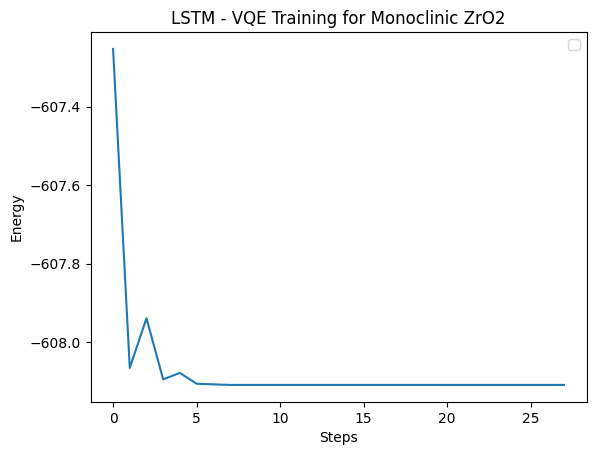

Estimated ground state energy of Monoclinic ZrO2: -608.1088065547855


In [86]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

## 下面这个是一个比较好的 3轨道优化结果，27,28,29o 2e

In [15]:
energy_list      ##一个比较好的结果

[-606.2223451747743,
 -607.327493525157,
 -607.260406720082,
 -607.6019297274783,
 -607.6608562438736,
 -607.7804114546201,
 -608.0243577882695,
 -608.0929706844441,
 -608.1043151703199,
 -608.1087802055463,
 -608.1087916385,
 -608.1087973100751,
 -608.1087973115882,
 -608.1087973142255,
 -608.1087973190706,
 -608.1087973281218,
 -608.1087973450675,
 -608.1087973765565,
 -608.1087974341538,
 -608.1087975370908,
 -608.1087977159596,
 -608.1087980197811,
 -608.1087985340587,
 -608.1087994050911,
 -608.1088007747238,
 -608.1088025234029,
 -608.108805351644,
 -608.1088091236202,
 -608.1088096395723,
 -608.1088096526229,
 -608.1088096547339,
 -608.1088096547896]

In [27]:
L1=[-606.2223451747743,
 -607.327493525157,
 -607.260406720082,
 -607.6019297274783,
 -607.6608562438736,
 -607.7804114546201,
 -608.0243577882695,
 -608.0929706844441,
 -608.1043151703199,
 -608.1087802055463,
 -608.1087916385,
 -608.1087973100751,
 -608.1087973115882,
 -608.1087973142255,
 -608.1087973190706,
 -608.1087973281218,
 -608.1087973450675,
 -608.1087973765565,
 -608.1087974341538,
 -608.1087975370908,
 -608.1087977159596,
 -608.1087980197811,
 -608.1087985340587,
 -608.1087994050911,
 -608.1088007747238,
 -608.1088025234029,
 -608.108805351644,
 -608.1088091236202,
 -608.1088096395723,
 -608.1088096526229,
 -608.1088096547339,
 -608.1088096547896]

/tmp/ipykernel_784152/3920743744.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


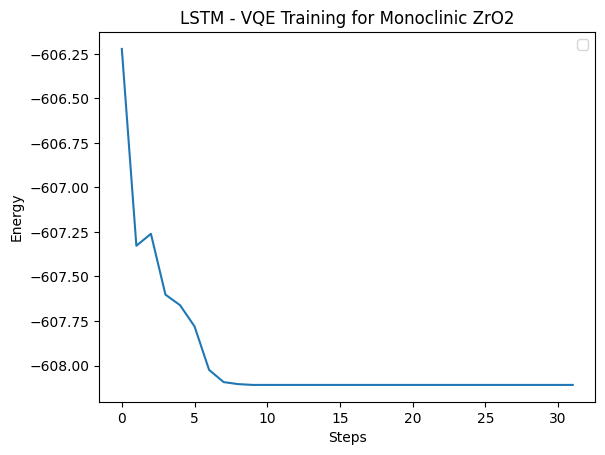

Estimated ground state energy of Monoclinic ZrO2: -608.1088096547896


In [28]:
# 绘制能量变化曲线
plt.figure()
plt.plot(L1)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {L1[-1]}")

## 4轨道

In [29]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=26, active_space_stop=30)

In [30]:
n_electrons

4

In [31]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                          Circuit Summary                           
╭──────────────────────┬───────────────────────────────────────────╮
│ Info                 │ value                                     │
├──────────────────────┼───────────────────────────────────────────┤
│ Number of qubit      │ 8                                         │
├──────────────────────┼───────────────────────────────────────────┤
│ Total number of gate │ 2692                                      │
│ Barrier              │ 640                                       │
│ Noise Channel        │ 0                                         │
│ Measurement          │ 0                                         │
├──────────────────────┼───────────────────────────────────────────┤
│ Parameter gate       │ 160                                       │
│ 14 ansatz parameters │ p0, p4, p1, p5, p2, p6, p3, p7, p8, p9... │
╰──────────────────────┴───────────────────────────────────────────╯

Number of parameters: 14


In [32]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [36]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [37]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -607.6014791264026
Step: 10,	energy: -608.0797095934826
Step: 15,	energy: -608.0988379596655
Step: 20,	energy: -608.1105473242901
Step: 25,	energy: -608.1106928594094
Step: 30,	energy: -608.1107114247355
Step: 35,	energy: -608.1107440894625
Step: 40,	energy: -608.1108016218211
Step: 45,	energy: -608.1112265779308
Step: 50,	energy: -608.1112579807791
Step: 55,	energy: -608.1112585073502
Step: 60,	energy: -608.1112650313486
Step: 65,	energy: -608.1112902287559
Step: 70,	energy: -608.1112931076387
Step: 75,	energy: -608.1113258860476
Step: 80,	energy: -608.1113367847929


/tmp/ipykernel_784152/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


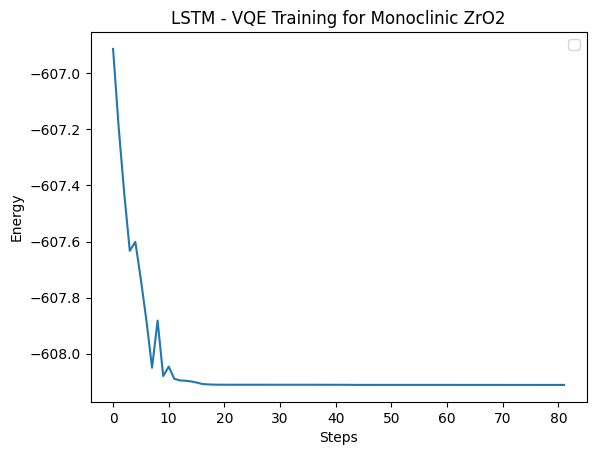

Estimated ground state energy of Monoclinic ZrO2: -608.1113367876088


In [38]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [39]:
energy_list

[-606.9131668959583,
 -607.1913509151461,
 -607.4268659857336,
 -607.6331080990229,
 -607.6014791264026,
 -607.7365834354555,
 -607.8830125623072,
 -608.0500733009094,
 -607.8819697892502,
 -608.0797095934826,
 -608.0461136024314,
 -608.089453757513,
 -608.0951869093855,
 -608.0964874473216,
 -608.0988379596655,
 -608.1028229718381,
 -608.1079035445082,
 -608.1094082016043,
 -608.1103279951815,
 -608.1105473242901,
 -608.1106087543268,
 -608.1106412871585,
 -608.110658503312,
 -608.1106788130783,
 -608.1106928594094,
 -608.1107013038367,
 -608.1107034461536,
 -608.1107048708601,
 -608.1107072731689,
 -608.1107114247355,
 -608.1107183803698,
 -608.1107286223319,
 -608.1107358350041,
 -608.1107401015523,
 -608.1107440894625,
 -608.1107504078918,
 -608.1107614998186,
 -608.1107825333336,
 -608.1108220712136,
 -608.1108016218211,
 -608.1108468829356,
 -608.1108906498291,
 -608.1109709085777,
 -608.1111050772746,
 -608.1112265779308,
 -608.111235576651,
 -608.1112402746561,
 -608.1112480761

## 一个比较好的4轨道优化结果 26,27,28,29o 4e

In [87]:
L4=[-606.9131668959583,-607.1913509151461,-607.4268659857336,-607.6331080990229,-607.6014791264026,-607.7365834354555,-607.8830125623072,-608.0500733009094,
 -607.8819697892502,-608.0797095934826,-608.0461136024314,-608.089453757513,-608.0951869093855,-608.0964874473216,-608.0988379596655,-608.1028229718381,-608.1079035445082,
 -608.1094082016043,-608.1103279951815,-608.1105473242901,-608.1106087543268,-608.1106412871585,-608.110658503312,-608.1106788130783,-608.1106928594094,
 -608.1107013038367,-608.1107034461536,-608.1107048708601,-608.1107072731689,-608.1107114247355,-608.1107183803698,-608.1107286223319,
 -608.1107358350041,-608.1107401015523,-608.1107440894625,-608.1107504078918,-608.1107614998186,-608.1107825333336,-608.1108220712136,
 -608.1108016218211,-608.1108468829356,-608.1108906498291,-608.1109709085777,-608.1111050772746,-608.1112265779308,-608.111235576651,
 -608.1112402746561,-608.1112480761027,-608.1112569874422,-608.1112579807791,-608.1112581618576,-608.111258193657,-608.1112582467703,-608.1112583398063,-608.1112585073502,
 -608.1112588120898,-608.1112593651306,-608.1112603565393,-608.111262093859,-608.1112650313486,-608.1112697235586,-608.1112764177603,
 -608.1112825418384,-608.1112884237435,-608.1112902287559,-608.1112904993794,-608.1112907006184,-608.111291069479,-608.111291770717,
 -608.1112931076387,-608.1112956279194,-608.1113002430043,-608.1113081221276,-608.1113190056575,-608.1113258860476,-608.1113330560233,
 -608.1113360677157,-608.1113364830499,-608.1113367775449,-608.1113367847929,-608.1113367875276,-608.1113367876088]

In [35]:
Menergy4 = energy_list

## 5轨道，26,27,28,29,30

In [88]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=26, active_space_stop=31)

In [89]:
n_electrons

4

In [90]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [91]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [122]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [123]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -607.5032210382833
Step: 10,	energy: -608.0716905067836
Step: 15,	energy: -608.0916602736102
Step: 20,	energy: -608.0996333908806
Step: 25,	energy: -608.108736194379
Step: 30,	energy: -608.1183109317132
Step: 35,	energy: -608.1196512432201
Step: 40,	energy: -608.1196830680769
Step: 45,	energy: -608.1196947529648
Step: 50,	energy: -608.1197069743497
Step: 55,	energy: -608.1197375243902
Step: 60,	energy: -608.119774369961
Step: 65,	energy: -608.1198081266252
Step: 70,	energy: -608.1198300039881
Step: 75,	energy: -608.1198363000669
Step: 80,	energy: -608.1198448044247
Step: 85,	energy: -608.1198462148691
Step: 90,	energy: -608.11985108378
Step: 95,	energy: -608.1198553093338
Step: 100,	energy: -608.1198616296091
Step: 105,	energy: -608.1198662356657
Step: 110,	energy: -608.1198678065426
Step: 115,	energy: -608.119871428215
Step: 120,	energy: -608.1198744723014
Step: 125,	energy: -608.1198746070783
Step: 130,	energy: -608.1198768084713
Step: 135,	energy: -608.1198953513101

/tmp/ipykernel_784152/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


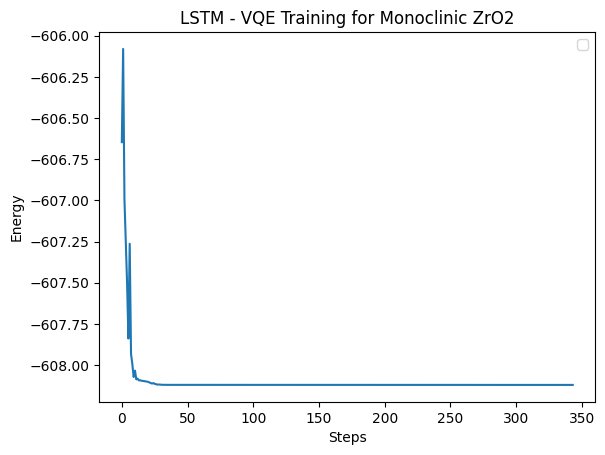

Estimated ground state energy of Monoclinic ZrO2: -608.1200560844345


In [124]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

## 好结果

In [115]:
L5=[-606.0996312279549,-606.413663986845,-606.8224025701811,-607.1887424766943,-607.2116194445291,-607.4365171672761,-607.7056663173664,
 -607.655584030469,-607.8288893767112,-608.0027410332631,-607.964183251506,-608.085089225295,-608.0403527251626,-608.0960563743715,-608.1101446940587,-608.1080124632982,
 -608.1152426424358,-608.1156051675429,-608.1162930828498,-608.1175198207596,-608.1191804325383,-608.1194845258115,-608.119533999168,-608.1195550510364,
 -608.1195789868901,-608.119587066474,-608.1195990750153,-608.1196071005094,-608.1196090241401,-608.1196092566863,-608.1196093888135,
 -608.11960952903,-608.1196095843487,-608.1196095976411,-608.1196096025792,-608.1196096043902,-608.1196096046281]

In [59]:
Menergy5 = energy_list

## 6轨道，26,27,28,29,30,31

In [129]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=25, active_space_stop=32)

In [130]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                             Circuit Summary                             
╭──────────────────────┬────────────────────────────────────────────────╮
│ Info                 │ value                                          │
├──────────────────────┼────────────────────────────────────────────────┤
│ Number of qubit      │ 14                                             │
├──────────────────────┼────────────────────────────────────────────────┤
│ Total number of gate │ 31414                                          │
│ Barrier              │ 5952                                           │
│ Noise Channel        │ 0                                              │
│ Measurement          │ 0                                              │
├──────────────────────┼────────────────────────────────────────────────┤
│ Parameter gate       │ 1488                                           │
│ 90 ansatz parameters │ p0, p12, p1, p13, p2, p14, p3, p15, p4, p16... │
╰──────────────────────┴────────────────────────────────────────────────╯

Number of parameters: 90


In [131]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [132]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [133]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -605.9143813186827
Step: 10,	energy: -606.855908805653
Step: 15,	energy: -607.5173707318992
Step: 20,	energy: -607.684276371614
Step: 25,	energy: -608.0724003492776
Step: 30,	energy: -608.1034312880773
Step: 35,	energy: -608.1165320716494
Step: 40,	energy: -608.1184204523523
Step: 45,	energy: -608.1189846581336
Step: 50,	energy: -608.1195123574197
Step: 55,	energy: -608.1195931770507
Step: 60,	energy: -608.1196077669988
Step: 65,	energy: -608.1196083911369
Step: 70,	energy: -608.1196083959247
Step: 75,	energy: -608.1196084392192


/tmp/ipykernel_798557/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


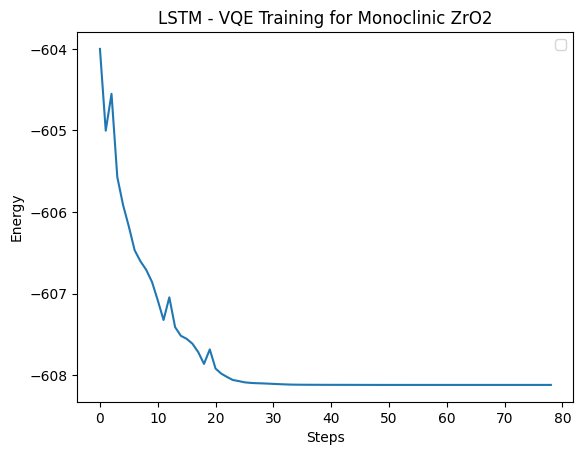

Estimated ground state energy of Monoclinic ZrO2: -608.1196084459457


In [135]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [103]:
L6=[-605.672301047877,-606.5444939553223,-607.4516068626691,-606.8206153485895,-607.7738003404322,-608.0930567990422,-607.9429015214613,-608.1082359419971,
 -608.10264535389,-608.1145218989572,-608.1154192311499,-608.1169598460074,-608.1187802517908,-608.1152184183702,-608.1192471580546,
 -608.1194431770058,-608.1195144395804,-608.1195830964606,-608.119602680474,-608.1196115682925,-608.1196140338002,-608.1196148442001,
 -608.1196151903938,-608.1196163470137,-608.1196174068508,-608.1196184315328,-608.1196194393417,-608.1196198404411,-608.1196199420286,-608.1196154447807,
 -608.1196254497687,-608.1196354589691,-608.1196654759829,-608.11968155072706,-608.119695564191,-608.1197056664327,-608.1197158491435,
 -608.1197261824265,-608.1197368374421,-608.1197405240147,-608.11975358861655,-608.1197610327018,-608.1197899881944,-608.11939234694424,
 -608.11981858447262,-608.119820405908,-608.1198411974679,-608.1198527011782,-608.1199024568, -608.11993698777984,
 -608.11995699310334,-608.11996700181475,-608.11996751531499,-608.119967703334617,-608.119968705019383,-608.119969705835852,-608.11997015947544,-608.119986705954737,
   -608.1199902167,-608.119993986736,-608.12000377656,-608.1200560844345]

/tmp/ipykernel_798557/2289154007.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


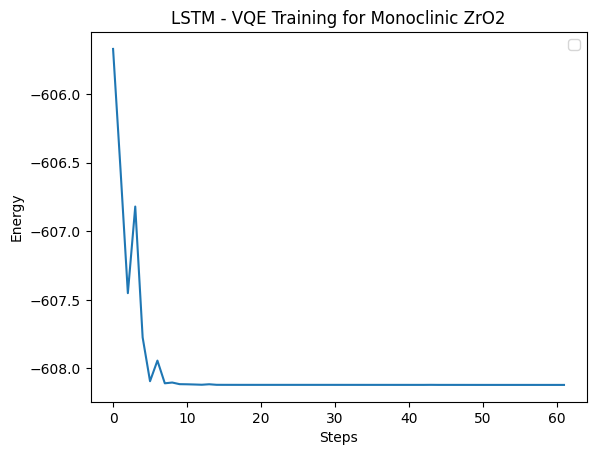

Estimated ground state energy of Monoclinic ZrO2: -608.1200560844345


In [104]:
# 绘制能量变化曲线
plt.figure()
plt.plot(L6)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {L6[-1]}")

In [136]:
L6=[-604.0002159008357,-605.0022810188616,-604.5509883490627,-605.5699723620663,-605.9143813186827,-606.1785268678395,-606.4679150344735,
-606.6031343857064,-606.708327627045,-606.855908805653,-607.082280290574,-607.3231046807604,-607.0461674790116,-607.4111269012307,
 -607.5173707318992,-607.5547479932594,-607.6144983744014,-607.7169176162487,-607.8619947912977,-607.684276371614,-607.9194987017919,
-607.9819184508173,-608.022782087438,-608.0594850487275,-608.0724003492776,-608.0877550138488,-608.0942819545259,-608.0984852774203,-608.1005361831996,-608.1034312880773,
 -608.1071124182358,-608.1100949832506,-608.1129654401137,-608.1154036088737,-608.1165320716494,-608.1173012721271,-608.1176778385843,
 -608.1179213069967,-608.118167705678,-608.1184204523523,-608.1186063275215,-608.1186856354029,-608.1187366424463,-608.118892308235,-608.1189846581336,
 -608.1190958285723,-608.1192350127545,-608.119421029637,-608.1194593599151,-608.1195123574197,-608.1195326496365,-608.1195411404894,
 -608.1195528393284,-608.1195719713877,-608.1195931770507,-608.119597514687,-608.1196041119626,-608.1196064689734,-608.1196074000156,
 -608.1196077669988,-608.1196082432696,-608.1196083645185,-608.1196083879116,-608.1196083898524,-608.1196083911369,-608.119608391331,
 -608.1196083916882,-608.1196083923692,-608.1196083936285,-608.1196083959247,-608.119608399967,-608.1196084066042,-608.1196084164322,
 -608.119608426772,-608.1196084392192,-608.1196084451785,-608.1196084458404,-608.1196084459093,-608.1196084459457]

[-604.0002159008357,
 -605.0022810188616,
 -604.5509883490627,
 -605.5699723620663,
 -605.9143813186827,
 -606.1785268678395,
 -606.4679150344735,
 -606.6031343857064,
 -606.708327627045,
 -606.855908805653,
 -607.082280290574,
 -607.3231046807604,
 -607.0461674790116,
 -607.4111269012307,
 -607.5173707318992,
 -607.5547479932594,
 -607.6144983744014,
 -607.7169176162487,
 -607.8619947912977,
 -607.684276371614,
 -607.9194987017919,
 -607.9819184508173,
 -608.022782087438,
 -608.0594850487275,
 -608.0724003492776,
 -608.0877550138488,
 -608.0942819545259,
 -608.0984852774203,
 -608.1005361831996,
 -608.1034312880773,
 -608.1071124182358,
 -608.1100949832506,
 -608.1129654401137,
 -608.1154036088737,
 -608.1165320716494,
 -608.1173012721271,
 -608.1176778385843,
 -608.1179213069967,
 -608.118167705678,
 -608.1184204523523,
 -608.1186063275215,
 -608.1186856354029,
 -608.1187366424463,
 -608.118892308235,
 -608.1189846581336,
 -608.1190958285723,
 -608.1192350127545,
 -608.119421029637,


/tmp/ipykernel_798557/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


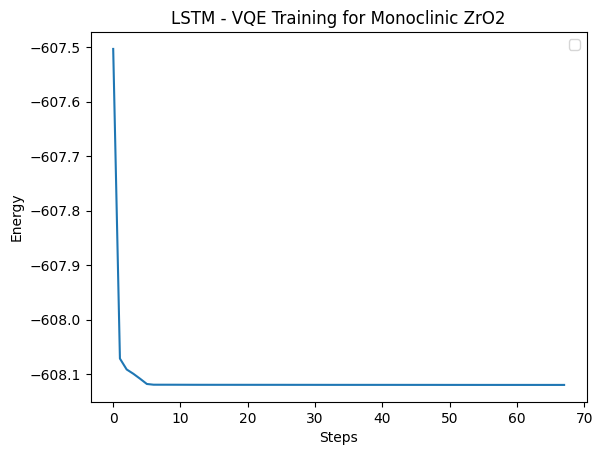

Estimated ground state energy of Monoclinic ZrO2: -608.1200560772278


In [116]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")